# Beyond PLSR: alternative models, same nested leave-one-session-out

**Question:** with no new samples, can a different technique beat the final PLSR model (0.79 % mean error on unseen sessions)?

**The shortlist was fixed before running anything**, so no model is picked because it happened to score best:

| # | Technique | What it adds that PLSR does not have |
|---|---|---|
| 0 | **PLSR (baseline)** | must reproduce 0.61 / 0.64 / 1.11 % — proves the protocol is identical |
| 1 | **EMSC + PLSR** | physics-based cleaning: removes brightness, offset and baseline tilt while keeping the chicory signal |
| 2 | **Mixing model (absorbance)** | treats every spectrum as robusta + chicory + scatter; no curve fitting beyond one direction |
| 3 | **Mixing model (Kubelka–Munk)** | same, after the Kubelka–Munk transform made for powders |
| 4 | **di-PLS** | PLS that also makes its components look the same in the new session (uses its unlabelled spectra) |
| 5 | **Ensemble: PLSR + PCR + SVR (linear)** | averages three models that fail in different places |
| 6 | **PLSR, median per dish** | a dish's value is the median of its super-patches, not the mean |
| 7 | **GPR on PLS scores** | gives every prediction its own ± uncertainty |

**Same protocol for every model** (copied unchanged from `robusta_chicory_nested_loso.ipynb`): the 33 calibration dishes, absorbance + offset,
trimming and super-patches rebuilt inside each round from the training sessions, inner leave-one-concentration-out with the one-standard-error
rule wherever a setting is tuned, scored as error per dish on the held-out session.

**Verdicts** come from a paired bootstrap against PLSR (dishes resampled within each session): *better* or *worse* only when the 95 % interval
of the difference excludes zero; otherwise *tie*.

**Extra test, new here:** the final models (trained on all three sessions) predict pure chicory (CH100, true 100 %), which no model was trained
on, and the unknowns A, B, C.

## 1. Setup, data and building blocks (copied from the final notebook)

In [1]:
import os
import json, pickle, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from sklearn.cross_decomposition import PLSRegression
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.linear_model import Ridge, ElasticNet, LinearRegression
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import mean_squared_error, r2_score

warnings.filterwarnings("ignore")

# ------------------------------- EDIT -------------------------------
BASE    = Path(os.environ.get("COFFEE_DATA", "."))
OLD_CSV = BASE / "samples_out" / "training_samples.csv"     # sessions 1 and 2
NEW_CSV = BASE / "batch3_out"  / "training_samples.csv"     # session 3
OUT     = BASE / "advanced_models"
LEVELS_KEEP = [0, 5, 10, 15, 20, 25, 30, 35, 40, 45, 50]     # % chicory: RB100 + 5-50 %
WL_MIN, WL_MAX = 1000.0, 2450.0
TRIM_PCT, K_UNIT = 10, 8          # trimming and super-patch size, as in the existing pipeline
N_BOOT = 2000
# ---------------------------------------------------------------------

OUT.mkdir(exist_ok=True, parents=True)
RNG = np.random.default_rng(0)

SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
S_COLOR  = {1: "#2a78d6", 2: "#eb6834", 3: "#1baf7a"}   # one colour and one marker per session
S_MARKER = {1: "o", 2: "s", 3: "^"}
HIGHLIGHT, OTHER = "#2a78d6", "#c3c2b7"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "font.size": 10.5,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlecolor": INK, "text.color": INK,
    "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": .6,
    "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 2, "legend.frameon": False, "legend.fontsize": 9,
})
BANDS = [(1450, "O–H water"), (1730, "C–H lipid"), (1940, "O–H water"),
         (2100, "C–O carbohydrate"), (2310, "C–H combination")]
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import DotProduct, RBF, WhiteKernel, ConstantKernel


In [2]:
old = pd.read_csv(OLD_CSV)
new = pd.read_csv(NEW_CSV)
for c in ("scan", "group", "plate"):
    new[c] = new[c].astype(str) + "_b3"        # keep session-3 plate ids distinct
DATA = pd.concat([old, new], ignore_index=True)
DATA = DATA[DATA.species.isin(["robusta", "robusta_chicory"])
            & (DATA.role == "calibration")
            & DATA.chicory_pct.isin(LEVELS_KEEP)].reset_index(drop=True)
DATA["session"] = DATA["day"].astype(int)
assert sorted(DATA.chicory_pct.unique()) == LEVELS_KEEP, sorted(DATA.chicory_pct.unique())

wc = [c for c in DATA.columns if c.replace(".", "", 1).isdigit()]
wl_all = np.array([float(c) for c in wc])
BM = (wl_all >= WL_MIN) & (wl_all <= WL_MAX)
WL, COLS = wl_all[BM], [c for c, k in zip(wc, BM) if k]

def preprocess(R):
    # absorbance, then remove each spectrum's own offset: a multiplicative brightness change
    # between acquisitions becomes an additive constant in log space and is subtracted away
    R = np.clip(np.asarray(R, float), 1e-3, None)
    Z = np.log10(1.0 / R)
    return Z - Z.mean(-1, keepdims=True)

Z       = preprocess(DATA[COLS].values)
SESSION = DATA["session"].to_numpy()
GROUP   = DATA["group"].astype(str).to_numpy()
Y       = DATA["chicory_pct"].to_numpy(float)

print(f"{len(DATA)} patches | {DATA.group.nunique()} plates | {len(WL)} bands ({WL[0]:.0f}-{WL[-1]:.0f} nm)")
print(DATA.groupby(["session", "label"]).agg(chicory=("chicory_pct", "first"), plates=("group", "nunique"),
                                             patches=("sample_id", "size")).to_string())

4910 patches | 33 plates | 266 bands (1001-2446 nm)
                   chicory  plates  patches
session label                              
1       RB100          0.0       3      410
2       RB[50:50]     50.0       3      450
        RB[60:40]     40.0       3      450
        RB[70:30]     30.0       3      450
        RB[80:20]     20.0       3      450
        RB[90:10]     10.0       3      450
3       RB[55:45]     45.0       3      450
        RB[65:35]     35.0       3      450
        RB[75:25]     25.0       3      450
        RB[85:15]     15.0       3      450
        RB[95:5]       5.0       3      450


In [3]:
META = ["session", "capture", "label", "group", "chicory_pct", "patch_row", "patch_col"]
_UNITS = {}

def units(train_sessions, k=K_UNIT):
    key = tuple(sorted(train_sessions))
    if key in _UNITS:
        return _UNITS[key]
    tr = np.isin(SESSION, key)
    ref = PLSRegression(n_components=4).fit(Z[tr], Y[tr])
    mu = Z[tr].mean(0)
    T = (Z - mu) @ ref.x_rotations_
    q = np.sum(((Z - mu) - T @ ref.x_loadings_.T) ** 2, axis=1)
    keep = pd.Series(q).groupby(GROUP).rank(pct=True).to_numpy() <= 1 - TRIM_PCT / 100
    idx = []
    for g in pd.unique(GROUP):
        ii = np.where((GROUP == g) & keep)[0]
        if len(ii) < k:
            continue
        n = max(1, len(ii) // k)
        lab = KMeans(n_clusters=n, n_init=5, random_state=0).fit_predict(
            DATA.loc[ii, ["patch_row", "patch_col"]].to_numpy(float))
        idx += [ii[lab == c] for c in range(n) if (lab == c).any()]
    ZU = np.array([Z[i].mean(0) for i in idx])
    UM = DATA.iloc[[i[0] for i in idx]][META].reset_index(drop=True)
    _UNITS[key] = (ZU, UM)
    return ZU, UM

def make(name, prm):
    if name == "PLSR":              return PLSRegression(n_components=prm)
    if name == "PCR":               return make_pipeline(PCA(n_components=prm), LinearRegression())
    if name == "Ridge":             return make_pipeline(StandardScaler(), Ridge(alpha=prm))
    if name == "ElasticNet":        return make_pipeline(StandardScaler(), ElasticNet(alpha=prm, l1_ratio=.5, max_iter=10000))
    if name == "SVR (linear)":      return make_pipeline(StandardScaler(), SVR(kernel="linear", C=prm))
    if name == "SVR (RBF)":         return make_pipeline(StandardScaler(), SVR(kernel="rbf", C=prm, gamma="scale"))
    if name == "Random Forest":     return RandomForestRegressor(n_estimators=200, min_samples_leaf=prm, max_features=.33,
                                                                 random_state=0, n_jobs=-1)
    if name == "Gradient Boosting": return GradientBoostingRegressor(n_estimators=prm, learning_rate=.05, max_depth=3,
                                                                     subsample=.8, random_state=0)
    raise KeyError(name)

GRIDS = {    # simplest -> most complex
    "PLSR":              list(range(1, 13)),
    "PCR":               [1, 2, 3, 4, 5, 6, 8, 10, 12, 15],
    "Ridge":             [1000, 300, 100, 30, 10, 3, 1, .3, .1],
    "ElasticNet":        [1, .3, .1, .03, .01, .003],
    "SVR (linear)":      [.01, .1, 1, 10],
    "SVR (RBF)":         [1, 10, 100, 1000],
    "Random Forest":     [20, 10, 5, 2, 1],
    "Gradient Boosting": [50, 100, 200, 400],
}
PARAM = {"PLSR": "latent variables", "PCR": "components", "Ridge": "alpha", "ElasticNet": "alpha",
         "SVR (linear)": "C", "SVR (RBF)": "C", "Random Forest": "min_samples_leaf", "Gradient Boosting": "n_estimators"}

def predict(model, X):
    return np.asarray(model.predict(X)).ravel()

def rmse(a, b):
    return float(np.sqrt(mean_squared_error(a, b)))

def plate_rmse(y, p, g):
    t = pd.DataFrame(dict(g=g, y=y, p=p)).groupby("g")[["y", "p"]].mean()
    return rmse(t.y, t.p)

def tune(name, X, y, g):
    rows = []
    for prm in GRIDS[name]:
        fold = []
        for a, b in LeaveOneGroupOut().split(X, y, groups=y):
            fold.append(plate_rmse(y[b], predict(make(name, prm).fit(X[a], y[a]), X[b]), g[b]))
        rows.append(dict(param=prm, mean=float(np.mean(fold)), se=float(np.std(fold, ddof=1) / np.sqrt(len(fold)))))
    T = pd.DataFrame(rows)
    best = int(T["mean"].idxmin())
    pick = int(np.flatnonzero(T["mean"].to_numpy() <= T.loc[best, "mean"] + T.loc[best, "se"])[0])
    T["chosen"] = np.arange(len(T)) == pick
    return GRIDS[name][pick], T

def score(d):
    plate  = d.groupby(["group", "y"], as_index=False)["p"].mean()
    sample = d.groupby(["label", "y"], as_index=False)["p"].mean()
    out = dict(levels=int(d.y.nunique()), plates=len(plate), units=len(d),
               rmsep_unit=rmse(d.y, d.p), rmsep_plate=rmse(plate.y, plate.p),
               rmsep_sample=rmse(sample.y, sample.p), bias=float((plate.p - plate.y).mean()),
               r2=np.nan, slope=np.nan, intercept=np.nan)
    if d.y.nunique() >= 3:
        out["r2"] = float(r2_score(plate.y, plate.p))
        out["slope"], out["intercept"] = map(float, np.polyfit(plate.y, plate.p, 1))
    return out

def linear_coef(m):
    if isinstance(m, PLSRegression):
        c = np.asarray(m.coef_)
        return c.ravel() if c.size == WL.size else c.T.ravel()
    if isinstance(m, Pipeline):
        steps, last = m.named_steps, m.steps[-1][1]
        if isinstance(last, LinearRegression) and "pca" in steps:
            return steps["pca"].components_.T @ np.ravel(last.coef_)
        if "standardscaler" in steps and hasattr(last, "coef_"):
            return np.ravel(last.coef_) / steps["standardscaler"].scale_
    return None

## 2. All samples and super-patches that keep track of their patches

Pure chicory, A, B, C and arabica are added only so the final models can be asked about them; they never enter training.
`build_units()` is the same trimming and super-patch rule as `units()`, but it also returns the reflectance of each super-patch (needed for
Kubelka–Munk). The check at the end confirms it reproduces `units()` exactly.

In [4]:
EXTRA_LABELS = ["CH100", "A", "B", "C", "AB100"]
ext = old[old.label.isin(EXTRA_LABELS)].reset_index(drop=True)
ext["session"] = ext["day"].astype(int)
ALL = pd.concat([DATA.assign(is_cal=True), ext.assign(is_cal=False)], ignore_index=True)
R_ALL = np.clip(ALL[COLS].to_numpy(float), 1e-3, None)
Z_ALL = preprocess(R_ALL)
G_ALL = ALL["group"].astype(str).to_numpy()
S_ALL = ALL["session"].to_numpy()
Y_ALL = ALL["chicory_pct"].to_numpy(float)
CAL = ALL["is_cal"].to_numpy()
POS = ALL[["patch_row", "patch_col"]].to_numpy(float)
LABEL = ALL["label"].to_numpy()


def build_units(train, k=K_UNIT):
    fit = CAL & np.isin(S_ALL, train)
    ref = PLSRegression(n_components=4).fit(Z_ALL[fit], Y_ALL[fit])
    mu = Z_ALL[fit].mean(0)
    T = (Z_ALL - mu) @ ref.x_rotations_
    q = np.sum(((Z_ALL - mu) - T @ ref.x_loadings_.T) ** 2, axis=1)
    keep = pd.Series(q).groupby(G_ALL).rank(pct=True).to_numpy() <= 1 - TRIM_PCT / 100
    idx = []
    for g in pd.unique(G_ALL):
        ii = np.where((G_ALL == g) & keep)[0]
        if len(ii) < k:
            continue
        n = max(1, len(ii) // k)
        lab = KMeans(n_clusters=n, n_init=5, random_state=0).fit_predict(POS[ii])
        idx += [ii[lab == c] for c in range(n) if (lab == c).any()]
    U = pd.DataFrame(dict(group=[G_ALL[i[0]] for i in idx], session=[S_ALL[i[0]] for i in idx], label=[LABEL[i[0]] for i in idx],
                          y=[Y_ALL[i[0]] for i in idx], cal=[CAL[i[0]] for i in idx]))
    return np.array([Z_ALL[i].mean(0) for i in idx]), np.array([R_ALL[i].mean(0) for i in idx]), U


ZU_chk, _, U_chk = build_units([2, 3])
ZU_ref, UM_ref = units([2, 3])
print("extra samples:", ext.groupby("label").size().to_dict())
print("build_units reproduces units():", np.allclose(ZU_chk[U_chk.cal.to_numpy()], ZU_ref), len(ZU_ref), "calibration super-patches")

extra samples: {'A': 401, 'AB100': 450, 'B': 450, 'C': 436, 'CH100': 436}
build_units reproduces units(): True 524 calibration super-patches


## 3. The techniques

- **EMSC** fits every spectrum as `offset + b × (mean spectrum) + h × (chicory direction) + linear and curved baseline`. The baseline terms and
  `b` are removed; the chemistry (`h × chicory direction`) stays. The mean spectrum and the chicory direction come from the training sessions only.
- **Mixing model** uses the same fit but reads the answer straight from it: `h ÷ b` is how far the sample is along the robusta→chicory
  direction, converted to % with one straight-line calibration on the training data. No other fitting.
- **Kubelka–Munk** transform `f(R) = (1 − R)² / 2R`, the standard transform for light scattered by powders.
- **di-PLS** penalises components whose spread differs between the training sessions and the new session (strength λ). λ cannot be tuned
  honestly here: tuning would need a second labelled session per round. It is therefore shown at three strengths as a sensitivity check,
  not as a model to select. Each round uses PLSR's number of latent variables.
- **GPR** is fitted on PLSR's components (same number as PLSR chose), with a linear + smooth kernel and a noise term.

In [5]:
LAM = np.linspace(-1, 1, len(WL))
km = lambda R: (1 - R) ** 2 / (2 * R)


def emsc_fit(Ztr, ytr):
    m = Ztr.mean(0); yc = ytr - ytr.mean()
    k = yc @ (Ztr - m) / (yc @ yc)                       # change in the spectrum per % chicory, from training only
    return dict(B=np.column_stack([np.ones_like(LAM), m, k, LAM, LAM ** 2]))


def emsc_apply(Zx, P):
    a, b, h, d, e = np.linalg.lstsq(P["B"], Zx.T, rcond=None)[0]
    corrected = (Zx - a[:, None] - np.outer(d, LAM) - np.outer(e, LAM ** 2)) / b[:, None]
    return corrected, h / b


def mixing_predict(Ftr, ytr, Fx):
    P = emsc_fit(Ftr, ytr)
    slope, icpt = np.polyfit(emsc_apply(Ftr, P)[1], ytr, 1)
    return slope * emsc_apply(Fx, P)[1] + icpt


def dipls_predict(Xs, ys, Xt, A, lam):
    mx, sx, my = Xs.mean(0), Xs.std(0, ddof=1), ys.mean()        # scaled like sklearn's PLSRegression
    X = (Xs - mx) / sx; y = ys - my
    Xs_c = X.copy(); Xt_c = (Xt - Xt.mean(0)) / sx
    Wl, Pl, ql = [], [], []
    for _ in range(A):
        w = (y @ X) / (y @ y)
        if lam > 0:
            D = Xs_c.T @ Xs_c / (len(Xs_c) - 1) - Xt_c.T @ Xt_c / (len(Xt_c) - 1)
            ev, V = np.linalg.eigh(D)
            w = np.linalg.solve(np.eye(len(w)) + lam * ((V * np.abs(ev)) @ V.T) / np.abs(ev).max(), w)
        w = w / np.linalg.norm(w)
        t = X @ w; p = X.T @ t / (t @ t); q = (y @ t) / (t @ t)
        X = X - np.outer(t, p); y = y - q * t
        ts = Xs_c @ w; Xs_c = Xs_c - np.outer(ts, Xs_c.T @ ts / (ts @ ts))
        tt = Xt_c @ w; Xt_c = Xt_c - np.outer(tt, Xt_c.T @ tt / (tt @ tt))
        Wl.append(w); Pl.append(p); ql.append(q)
    W, Pm, qv = np.array(Wl).T, np.array(Pl).T, np.array(ql)
    return ((Xt - mx) / sx) @ (W @ np.linalg.solve(Pm.T @ W, qv)) + my


def gpr_predict(Xtr, ytr, Xx, A):
    pls = PLSRegression(n_components=A).fit(Xtr, ytr)
    sc = StandardScaler().fit(pls.transform(Xtr))
    kern = ConstantKernel(1.0) * DotProduct(1.0) + ConstantKernel(1.0) * RBF(np.full(A, 3.0)) + WhiteKernel(0.1)
    gp = GaussianProcessRegressor(kern, normalize_y=True, n_restarts_optimizer=2, random_state=0)
    gp.fit(sc.transform(pls.transform(Xtr)), ytr)
    return gp.predict(sc.transform(pls.transform(Xx)), return_std=True)


DIPLS_LAMBDAS = (0.1, 1.0, 10.0)
MODELS = ["PLSR (baseline)", "EMSC + PLSR", "Mixing model (absorbance)", "Mixing model (Kubelka–Munk)"] + \
         [f"di-PLS (λ = {l:g})" for l in DIPLS_LAMBDAS] + ["Ensemble: PLSR + PCR + SVR", "PLSR, median per dish", "GPR on PLS scores"]

## 4. Nested leave-one-session-out, every technique

Takes a few minutes. The first printed line per round checks that di-PLS with λ = 0 equals PLSR, so the di-PLS code is sound.

In [6]:
rows, tuned = [], []
for held in (1, 2, 3):
    train = [s for s in (1, 2, 3) if s != held]
    ZU, RU, U = build_units(train)
    tr = (U.cal & U.session.isin(train)).to_numpy(); te = (U.cal & (U.session == held)).to_numpy()
    ytr, gtr = U.y[tr].to_numpy(), U.group[tr].to_numpy()
    out = {}
    base = {}
    for name in ("PLSR", "PCR", "SVR (linear)"):
        prm, _ = tune(name, ZU[tr], ytr, gtr)
        base[name] = (prm, predict(make(name, prm).fit(ZU[tr], ytr), ZU[te]))
    A = int(base["PLSR"][0])
    out["PLSR (baseline)"] = base["PLSR"][1]
    out["PLSR, median per dish"] = base["PLSR"][1]
    out["Ensemble: PLSR + PCR + SVR"] = np.mean([base[n][1] for n in base], axis=0)
    P = emsc_fit(ZU[tr], ytr)
    Ctr, Cte = emsc_apply(ZU[tr], P)[0], emsc_apply(ZU[te], P)[0]
    prm_e, _ = tune("PLSR", Ctr, ytr, gtr)
    out["EMSC + PLSR"] = predict(make("PLSR", prm_e).fit(Ctr, ytr), Cte)
    out["Mixing model (absorbance)"] = mixing_predict(ZU[tr], ytr, ZU[te])
    F = km(RU)
    out["Mixing model (Kubelka–Munk)"] = mixing_predict(F[tr], ytr, F[te])
    check = np.abs(dipls_predict(ZU[tr], ytr, ZU[te], A, 0.0) - out["PLSR (baseline)"]).max()
    for lam in DIPLS_LAMBDAS:
        out[f"di-PLS (λ = {lam:g})"] = dipls_predict(ZU[tr], ytr, ZU[te], A, lam)
    mu, sd = gpr_predict(ZU[tr], ytr, ZU[te], A)
    out["GPR on PLS scores"] = mu
    for name in MODELS:
        rows.append(pd.DataFrame(dict(model=name, fold=held, group=U.group[te].to_numpy(), label=U.label[te].to_numpy(),
                                      y=U.y[te].to_numpy(), p=out[name], sd=sd if name.startswith("GPR") else np.nan)))
    tuned.append(dict(held_out=held, PLSR_LV=A, PCR=base["PCR"][0], SVR_C=base["SVR (linear)"][0], EMSC_PLSR_LV=prm_e))
    print(f"session {held} held out: {tr.sum()} train / {te.sum()} test super-patches | PLSR {A} LV, EMSC+PLSR {prm_e} LV | "
          f"di-PLS(λ=0) vs PLSR max difference {check:.2e}")
PRED = pd.concat(rows, ignore_index=True)
print(pd.DataFrame(tuned).to_string(index=False))

session 1 held out: 480 train / 44 test super-patches | PLSR 6 LV, EMSC+PLSR 3 LV | di-PLS(λ=0) vs PLSR max difference 2.49e-14


session 2 held out: 284 train / 240 test super-patches | PLSR 7 LV, EMSC+PLSR 5 LV | di-PLS(λ=0) vs PLSR max difference 2.84e-14


session 3 held out: 284 train / 240 test super-patches | PLSR 6 LV, EMSC+PLSR 6 LV | di-PLS(λ=0) vs PLSR max difference 7.11e-14
 held_out  PLSR_LV  PCR  SVR_C  EMSC_PLSR_LV
        1        6    5    0.1             3
        2        7    6    1.0             5
        3        6    5    0.1             6


## 5. Results: error per dish on the session each model never saw, and the verdict against PLSR

In [7]:
def dish_table(d, agg):
    return d.groupby(["fold", "group"], as_index=False).agg(y=("y", "first"), p=("p", agg))


def rmse_of(e): return float(np.sqrt(np.mean(np.square(e))))


per_session, dishes = [], {}
for name in MODELS:
    dt = dish_table(PRED[PRED.model == name], "median" if "median" in name else "mean")
    dishes[name] = dt
    for f in (1, 2, 3):
        e = (dt[dt.fold == f].p - dt[dt.fold == f].y).to_numpy()
        per_session.append(dict(model=name, held_out=f, rmsep=rmse_of(e), bias=float(e.mean()), dishes=len(e)))
PS = pd.DataFrame(per_session)

RNG = np.random.default_rng(0)
B = 2000
def boot_vs_baseline(name):
    a, b = dishes["PLSR (baseline)"], dishes[name]
    diff = np.zeros(B)
    for f in (1, 2, 3):
        ea = (a[a.fold == f].sort_values("group").p - a[a.fold == f].sort_values("group").y).to_numpy() ** 2
        eb = (b[b.fold == f].sort_values("group").p - b[b.fold == f].sort_values("group").y).to_numpy() ** 2
        ii = RNG.integers(0, len(ea), size=(B, len(ea)))
        diff += (np.sqrt(eb[ii].mean(1)) - np.sqrt(ea[ii].mean(1))) / 3
    return np.percentile(diff, [2.5, 97.5])


summary = []
for name in MODELS:
    s = PS[PS.model == name].set_index("held_out")
    dt = dishes[name]
    row = dict(model=name, S1=s.loc[1, "rmsep"], S2=s.loc[2, "rmsep"], S3=s.loc[3, "rmsep"], mean=s.rmsep.mean(), sd=s.rmsep.std(ddof=1),
               pooled=rmse_of(dt.p - dt.y), max_abs_bias=s.bias.abs().max())
    if name == "PLSR (baseline)":
        row.update(diff=0.0, ci_lo=np.nan, ci_hi=np.nan, verdict="baseline")
    else:
        lo, hi = boot_vs_baseline(name)
        row.update(diff=row["mean"] - PS[PS.model == "PLSR (baseline)"].rmsep.mean(), ci_lo=lo, ci_hi=hi,
                   verdict=("better" if hi < 0 else "worse" if lo > 0 else "tie") + (" (sensitivity, λ not tuned)" if name.startswith("di-PLS") else ""))
    summary.append(row)
SUM = pd.DataFrame(summary)
pd.set_option("display.width", 200)
print(SUM.round(3).to_string(index=False))

g = PRED[PRED.model == "GPR on PLS scores"]
cover = float(np.mean(np.abs(g.y - g.p) <= 1.96 * g.sd))
print(f"\nGPR uncertainty: average ± {g.sd.mean():.2f} % per super-patch; {100 * cover:.0f} % of super-patches fall inside their 95 % interval")

                      model    S1     S2    S3  mean    sd  pooled  max_abs_bias   diff  ci_lo  ci_hi                        verdict
            PLSR (baseline) 0.611  0.639 1.111 0.787 0.281   0.883         0.465  0.000    NaN    NaN                       baseline
                EMSC + PLSR 1.623  0.866 1.263 1.251 0.379   1.142         1.544  0.464  0.286  0.638                          worse
  Mixing model (absorbance) 8.445 10.124 6.510 8.360 1.809   8.505         8.425  7.573  6.574  8.435                          worse
Mixing model (Kubelka–Munk) 7.280 10.672 7.461 8.471 1.908   9.049         7.266  7.684  6.547  8.651                          worse
           di-PLS (λ = 0.1) 0.612  0.641 1.113 0.789 0.281   0.885         0.470  0.002 -0.014  0.019 tie (sensitivity, λ not tuned)
             di-PLS (λ = 1) 0.710  0.663 1.098 0.824 0.239   0.891         0.490  0.037 -0.087  0.133 tie (sensitivity, λ not tuned)
            di-PLS (λ = 10) 0.846  0.716 1.222 0.928 0.263   0.989   

## 6. Extrapolation test: the final models on samples nobody trained on

Each technique is refitted on all three sessions (as the final PLSR model was) and asked about pure chicory (true 100 %, far outside the
0–50 % training range), the unknowns A, B, C, and arabica. Only pure chicory has a known answer.

In [8]:
ZU, RU, U = build_units([1, 2, 3])
tr = U.cal.to_numpy(); ex = ~tr
ytr, gtr = U.y[tr].to_numpy(), U.group[tr].to_numpy()
fin = {}
base = {}
for name in ("PLSR", "PCR", "SVR (linear)"):
    prm, _ = tune(name, ZU[tr], ytr, gtr)
    base[name] = (prm, predict(make(name, prm).fit(ZU[tr], ytr), ZU[ex]))
A = int(base["PLSR"][0])
fin["PLSR (baseline)"] = base["PLSR"][1]
fin["Ensemble: PLSR + PCR + SVR"] = np.mean([base[n][1] for n in base], axis=0)
P = emsc_fit(ZU[tr], ytr); Ctr = emsc_apply(ZU[tr], P)[0]
prm_e, _ = tune("PLSR", Ctr, ytr, gtr)
fin["EMSC + PLSR"] = predict(make("PLSR", prm_e).fit(Ctr, ytr), emsc_apply(ZU[ex], P)[0])
fin["Mixing model (absorbance)"] = mixing_predict(ZU[tr], ytr, ZU[ex])
fin["Mixing model (Kubelka–Munk)"] = mixing_predict(km(RU[tr]), ytr, km(RU[ex]))
fin["GPR on PLS scores"], gsd = gpr_predict(ZU[tr], ytr, ZU[ex], A)
EX = []
for name, p in fin.items():
    d = pd.DataFrame(dict(label=U.label[ex].to_numpy(), group=U.group[ex].to_numpy(), p=p))
    per_dish = d.groupby(["label", "group"]).p.mean().groupby("label")
    EX.append(per_dish.mean().rename(name))
EXT = pd.concat(EX, axis=1).loc[["CH100", "A", "B", "C", "AB100"]].T
print(f"final models: PLSR {A} LV, EMSC + PLSR {prm_e} LV")
print("predicted chicory %, mean of each sample's 3 dishes (pure chicory is truly 100 %):")
print(EXT.round(1).to_string())

final models: PLSR 6 LV, EMSC + PLSR 4 LV
predicted chicory %, mean of each sample's 3 dishes (pure chicory is truly 100 %):
label                        CH100     A     B     C  AB100
PLSR (baseline)               87.9  31.3  50.9  38.5  -15.5
Ensemble: PLSR + PCR + SVR    88.8  33.1  53.4  41.6  -14.4
EMSC + PLSR                   82.2  28.5  45.1  32.8  -23.7
Mixing model (absorbance)     79.3  13.2  69.6  39.0  -13.9
Mixing model (Kubelka–Munk)   63.3  22.9  57.8  32.3  -31.0
GPR on PLS scores             87.9  29.6  51.6  37.2  -15.2


## 7. Figures and saved results

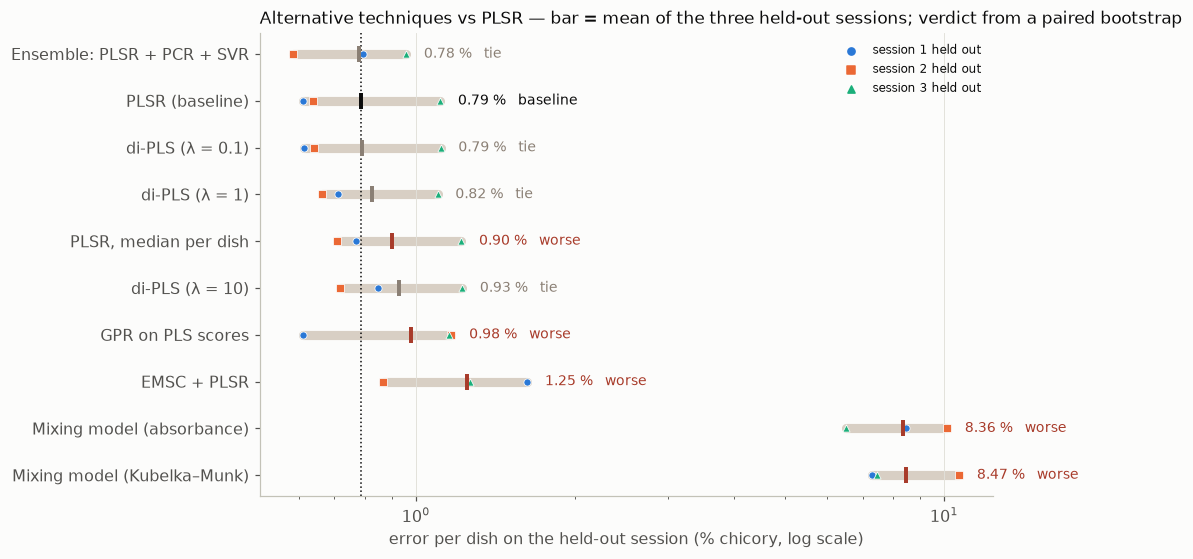

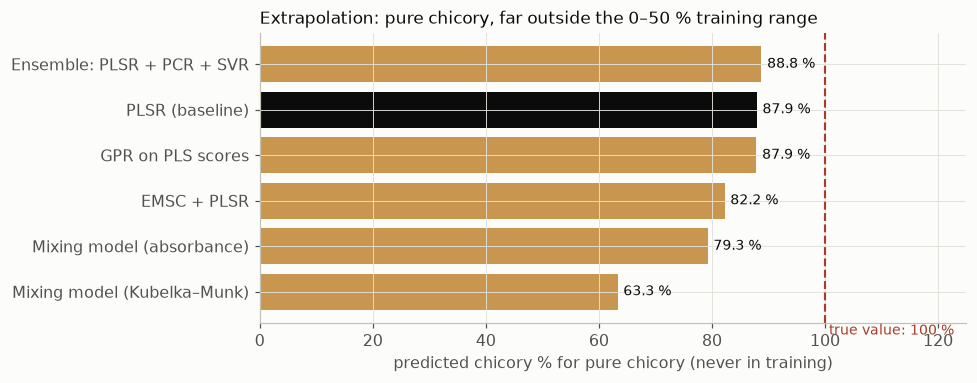

saved to /run/media/riyanvarghese/RIYAN HDD/coffee data/advanced_models


In [9]:
OUT.mkdir(exist_ok=True, parents=True)
order = SUM.sort_values("mean").model.tolist()
fig, ax = plt.subplots(figsize=(10, 5.2))
y = np.arange(len(order))[::-1]
for yi, name in zip(y, order):
    r = SUM.set_index("model").loc[name]
    v = PS[PS.model == name].sort_values("held_out")
    col = INK if name == "PLSR (baseline)" else (HIGHLIGHT if r.verdict.startswith("better") else ("#a83b2a" if r.verdict.startswith("worse") else "#8a7f74"))
    ax.plot([v.rmsep.min(), v.rmsep.max()], [yi, yi], color="#d8cfc4", lw=6, solid_capstyle="round", zorder=1)
    for s_, e_ in zip(v.held_out, v.rmsep):
        ax.scatter(e_, yi, s=22, color=S_COLOR[s_], marker=S_MARKER[s_], zorder=3, edgecolor="white", linewidth=.5)
    ax.scatter(r["mean"], yi, s=110, marker="|", color=col, linewidth=2.6, zorder=4)
    ax.text(v.rmsep.max() * 1.08, yi, f"{r['mean']:.2f} %   {r.verdict.split(' (')[0]}", va="center", fontsize=9, color=col)
ax.set_yticks(y, order); ax.set_xscale("log"); ax.set_xlabel("error per dish on the held-out session (% chicory, log scale)")
ax.axvline(SUM.set_index("model").loc["PLSR (baseline)", "mean"], color=INK, ls=":", lw=1)
for s_ in (1, 2, 3):
    ax.scatter([], [], color=S_COLOR[s_], marker=S_MARKER[s_], s=22, label=f"session {s_} held out")
ax.legend(loc="upper right", fontsize=8); ax.grid(axis="y", visible=False)
ax.set_title("Alternative techniques vs PLSR — bar = mean of the three held-out sessions; verdict from a paired bootstrap", loc="left", fontsize=11)
plt.tight_layout(); plt.savefig(OUT / "01_techniques_vs_plsr.png", bbox_inches="tight"); plt.show()

fig, ax = plt.subplots(figsize=(9, 3.6))
ch = EXT["CH100"].sort_values()
ax.barh(ch.index, ch.values, color=[INK if n == "PLSR (baseline)" else "#c8964f" for n in ch.index])
ax.axvline(100, color="#a83b2a", ls="--", lw=1.4); ax.text(100, -0.7, " true value: 100 %", color="#a83b2a", fontsize=9, va="top")
for i, v in enumerate(ch.values): ax.text(v + 1, i, f"{v:.1f} %", va="center", fontsize=9)
ax.set_xlim(0, 125); ax.set_xlabel("predicted chicory % for pure chicory (never in training)")
ax.set_title("Extrapolation: pure chicory, far outside the 0–50 % training range", loc="left", fontsize=11)
plt.tight_layout(); plt.savefig(OUT / "02_pure_chicory_extrapolation.png", bbox_inches="tight"); plt.show()

SUM.to_csv(OUT / "model_summary.csv", index=False)
PS.to_csv(OUT / "per_session.csv", index=False)
PRED.to_csv(OUT / "heldout_predictions_all_models.csv", index=False)
EXT.to_csv(OUT / "final_models_extra_samples.csv")
pd.DataFrame(tuned).to_csv(OUT / "settings_per_round.csv", index=False)
print("saved to", OUT)

## 8. How to read this

- **Baseline check:** PLSR must show 0.61 / 0.64 / 1.11 % (mean 0.79). If it does, every other row was measured under exactly the same conditions.
- **better / worse:** the 95 % bootstrap interval of the difference from PLSR lies entirely below / above zero. **tie:** it includes zero —
  the data cannot tell the two apart.
- **di-PLS rows** are a sensitivity check at three fixed strengths, not a model to choose: picking the best λ after seeing the results would
  be tuning on the test sessions.
- **Small differences are not detectable here.** Three sessions and 33 dishes give intervals of roughly ± 0.1–0.2 %.
- **Even a tie can be worth it** if the technique adds something PLSR cannot: predictions beyond 50 % chicory (mixing models — see the
  pure-chicory test), or a per-sample uncertainty (GPR).